In [1]:
import os
import time
import pandas as pd
import tarfile
import pickle
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support

import torch.optim as optim
import optuna
from tqdm import tqdm

from gpu_data_utilities import *
from models import *
from plotting import *

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
TAR_PATH = "data/cifar-100-python.tar.gz"
CKPT_DIR = "checkpoints"
RESULTS_DIR = "results"
SEED = 42
NUM_CLASSES = 100
DUMMY_ACC = 100.0 / NUM_CLASSES        

EPOCHS = 50   
PATIENCE = 10

# Pre-Tuned CNN parameters
BASELINE = dict(lr=1e-3, weight_decay=1e-4, dropout_rate=0.3, batch_size=64)
# Logistic Regression parameters (for comparison)
LOGREG = dict(lr=1e-2, weight_decay=1e-4, batch_size=64)

N_TRIALS = 30
N_EPOCHS = 10         
BATCH_SIZES = [32, 64, 128]
EVAL_BATCH_SIZE = 1024

np.random.seed(SEED)
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

## Data: one pass over the tar, everything onto the GPU

In [3]:
def load_cifar100(tar_path):
    """Read train / test / meta from the tar in ONE pass. Returns uint8 arrays shaped (N, 3, 32, 32)."""
    found = {}
    with tarfile.open(tar_path, "r:gz") as tar:
        for member in tar:
            name = os.path.basename(member.name)
            if member.isfile() and name in ("train", "test", "meta"):
                found[name] = pickle.load(tar.extractfile(member), encoding="bytes")
                if len(found) == 3:
                    break
    missing = {"train", "test", "meta"} - found.keys()
    if missing:
        raise FileNotFoundError(f"{tar_path} is missing: {sorted(missing)}")
    X_tr = found["train"][b"data"].reshape(-1, 3, 32, 32)
    X_te = found["test"][b"data"].reshape(-1, 3, 32, 32)
    y_tr = np.asarray(found["train"][b"fine_labels"])
    y_te = np.asarray(found["test"][b"fine_labels"])
    names = [n.decode("utf-8") for n in found["meta"][b"fine_label_names"]]
    return X_tr, y_tr, X_te, y_te, names


X_full, y_full, X_test_np, y_test_np, CLASS_NAMES = load_cifar100(TAR_PATH)

# Stratified 80/20 train/val split (same indices as before: random_state=42)
train_idx, val_idx = train_test_split(
    np.arange(len(y_full)), test_size=0.2, stratify=y_full, random_state=SEED
)


def to_gpu(X_np, y_np):
    return torch.from_numpy(np.ascontiguousarray(X_np)).to(device), torch.from_numpy(y_np).long().to(device)


X_train, y_train = to_gpu(X_full[train_idx], y_full[train_idx])   # uint8, augmented fresh every epoch
X_val_u8, y_val = to_gpu(X_full[val_idx], y_full[val_idx])
X_test_u8, y_test = to_gpu(X_test_np, y_test_np)

# Val / test never change: normalize once
X_val = make_epoch_tensor(X_val_u8)
X_test = make_epoch_tensor(X_test_u8)

print(f"train {tuple(X_train.shape)} | val {tuple(X_val.shape)} | test {tuple(X_test.shape)} | {len(CLASS_NAMES)} classes")

train (40000, 3, 32, 32) | val (10000, 3, 32, 32) | test (10000, 3, 32, 32) | 100 classes


## Models, training loop, evaluation

In [4]:
def make_cnn(dropout_rate):
    return Improved2DCNN(dropout_rate=dropout_rate, num_classes=NUM_CLASSES).to(device).to(memory_format=torch.channels_last)


def make_logreg():
    return LogisticRegressionBaseline(num_classes=NUM_CLASSES).to(device)


@torch.inference_mode()
def evaluate_gpu(model, X, y, return_preds=False, batch_size=EVAL_BATCH_SIZE):
    """X is a pre-normalized tensor. Everything stays on the GPU; one sync at the end."""
    model.eval()
    loss_sum = torch.zeros((), device=X.device)
    preds = []
    for i in range(0, X.size(0), batch_size):
        xb, yb = X[i : i + batch_size], y[i : i + batch_size]
        with torch.autocast(device.type, enabled=USE_AMP):
            out = model(xb)
        loss_sum += F.cross_entropy(out.float(), yb, reduction="sum")
        preds.append(out.argmax(1))
    preds = torch.cat(preds)
    n = X.size(0)
    loss = loss_sum.item() / n
    acc = 100.0 * (preds == y).sum().item() / n
    return (loss, acc, preds.cpu().numpy()) if return_preds else (loss, acc)


def fit(model, *, lr, weight_decay, batch_size, epochs, patience=None, trial=None, min_delta=0.01,
        desc="Training", verbose=True):
    """Train on (X_train, y_train), validate on (X_val, y_val). Cosine LR schedule over `epochs`.
    patience=None -> no early stopping (used by Optuna trials). With patience, the best-val-loss weights
    are restored at the end. Passing an Optuna `trial` enables per-epoch pruning."""
    crit = nn.CrossEntropyLoss()
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, fused=(device.type == "cuda"))
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    
    # Initialize best_loss to infinity instead of best_acc to 0
    best_loss, best_state, bad_epochs = float('inf'), None, 0

    n = X_train.size(0)
    steps = n // batch_size              
    n_used = steps * batch_size

    bar = tqdm(range(epochs), desc=desc, unit="epoch", disable=not verbose)
    for epoch in bar:
        model.train()
        perm = torch.randperm(n, device=device)
        Xe = make_epoch_tensor(X_train, perm, augment=True) 
        ye = y_train[perm]

        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), dtype=torch.long, device=device)
        for s in range(steps):
            lo = s * batch_size
            xb, yb = Xe[lo : lo + batch_size], ye[lo : lo + batch_size]

            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=USE_AMP):
                out = model(xb)
                loss = crit(out, yb)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            loss_sum += loss.detach() * batch_size          
            correct += (out.argmax(1) == yb).sum()
        sched.step()                                         

        train_loss, train_acc = loss_sum.item() / n_used, 100.0 * correct.item() / n_used
        val_loss, val_acc = evaluate_gpu(model, X_val, y_val)
        for k, v in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[k].append(v)
        bar.set_postfix(tr_loss=f"{train_loss:.3f}", val_loss=f"{val_loss:.3f}", val_acc=f"{val_acc:.2f}%")

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if patience is not None:
            # Track lowest val_loss. min_delta is now on the loss scale (e.g. 0.01)
            if val_loss < (best_loss - min_delta):
                best_loss, bad_epochs = val_loss, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad_epochs += 1
                if bad_epochs >= patience:
                    tqdm.write(f"Early stopping at epoch {epoch + 1} (best val loss {best_loss:.4f}).")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history


def save_run(path, model, history, train_time_s=None):
    torch.save({"model": model.state_dict(), "history": history, "train_time_s": train_time_s}, path)


def load_run(path, model):
    ckpt = torch.load(path, map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    return ckpt["history"], ckpt.get("train_time_s")

In [5]:
def timed_test(model, X, y):
    """Run the test set once and return (loss, acc, preds, seconds). Synchronizes so GPU time is counted."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    loss, acc, preds = evaluate_gpu(model, X, y, return_preds=True)   # ends with a GPU->CPU copy (sync)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return loss, acc, preds, time.perf_counter() - t0


def save_model_csv(name, history, y_true, y_pred, train_time_s, test_time_s, results_dir=None):
    """Save one model's results:
         <name>_history.csv  : per-epoch train/val loss and accuracy
         <name>_metrics.csv  : one row with test Accuracy / Precision / Recall / F1 (macro, %) and times (minutes)
       Returns the metrics dict (also used by the comparison plots)."""
    results_dir = results_dir or RESULTS_DIR
    slug = name.lower().replace(" ", "_")
    hist = pd.DataFrame({k: v for k, v in history.items() if isinstance(v, (list, tuple))})
    hist.insert(0, "epoch", range(1, len(hist) + 1))
    hist.to_csv(os.path.join(results_dir, f"{slug}_history.csv"), index=False)

    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    metrics = {
        "model": name,
        "accuracy": 100.0 * float(np.mean(np.asarray(y_true) == np.asarray(y_pred))),
        "precision": 100.0 * prec, "recall": 100.0 * rec, "f1": 100.0 * f1,
        "train_time_min": None if train_time_s is None else train_time_s / 60.0,
        "test_time_min": test_time_s / 60.0,
    }
    pd.DataFrame([metrics]).to_csv(os.path.join(results_dir, f"{slug}_metrics.csv"), index=False)
    print(f"Saved {slug}_history.csv and {slug}_metrics.csv -> {results_dir}/")
    return metrics

## Pre-tune 2D-CNN (saved after the first run)

Found checkpoint: loading checkpoints\cnn_baseline.pt


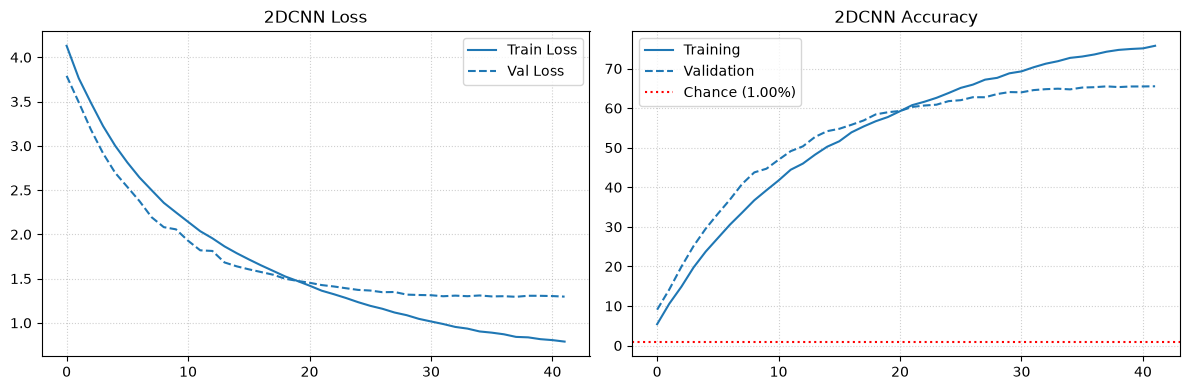


Final 2DCNN Test Acc: 64.82% (Loss: 1.2812)
Saved 2dcnn_history.csv and 2dcnn_metrics.csv -> results/


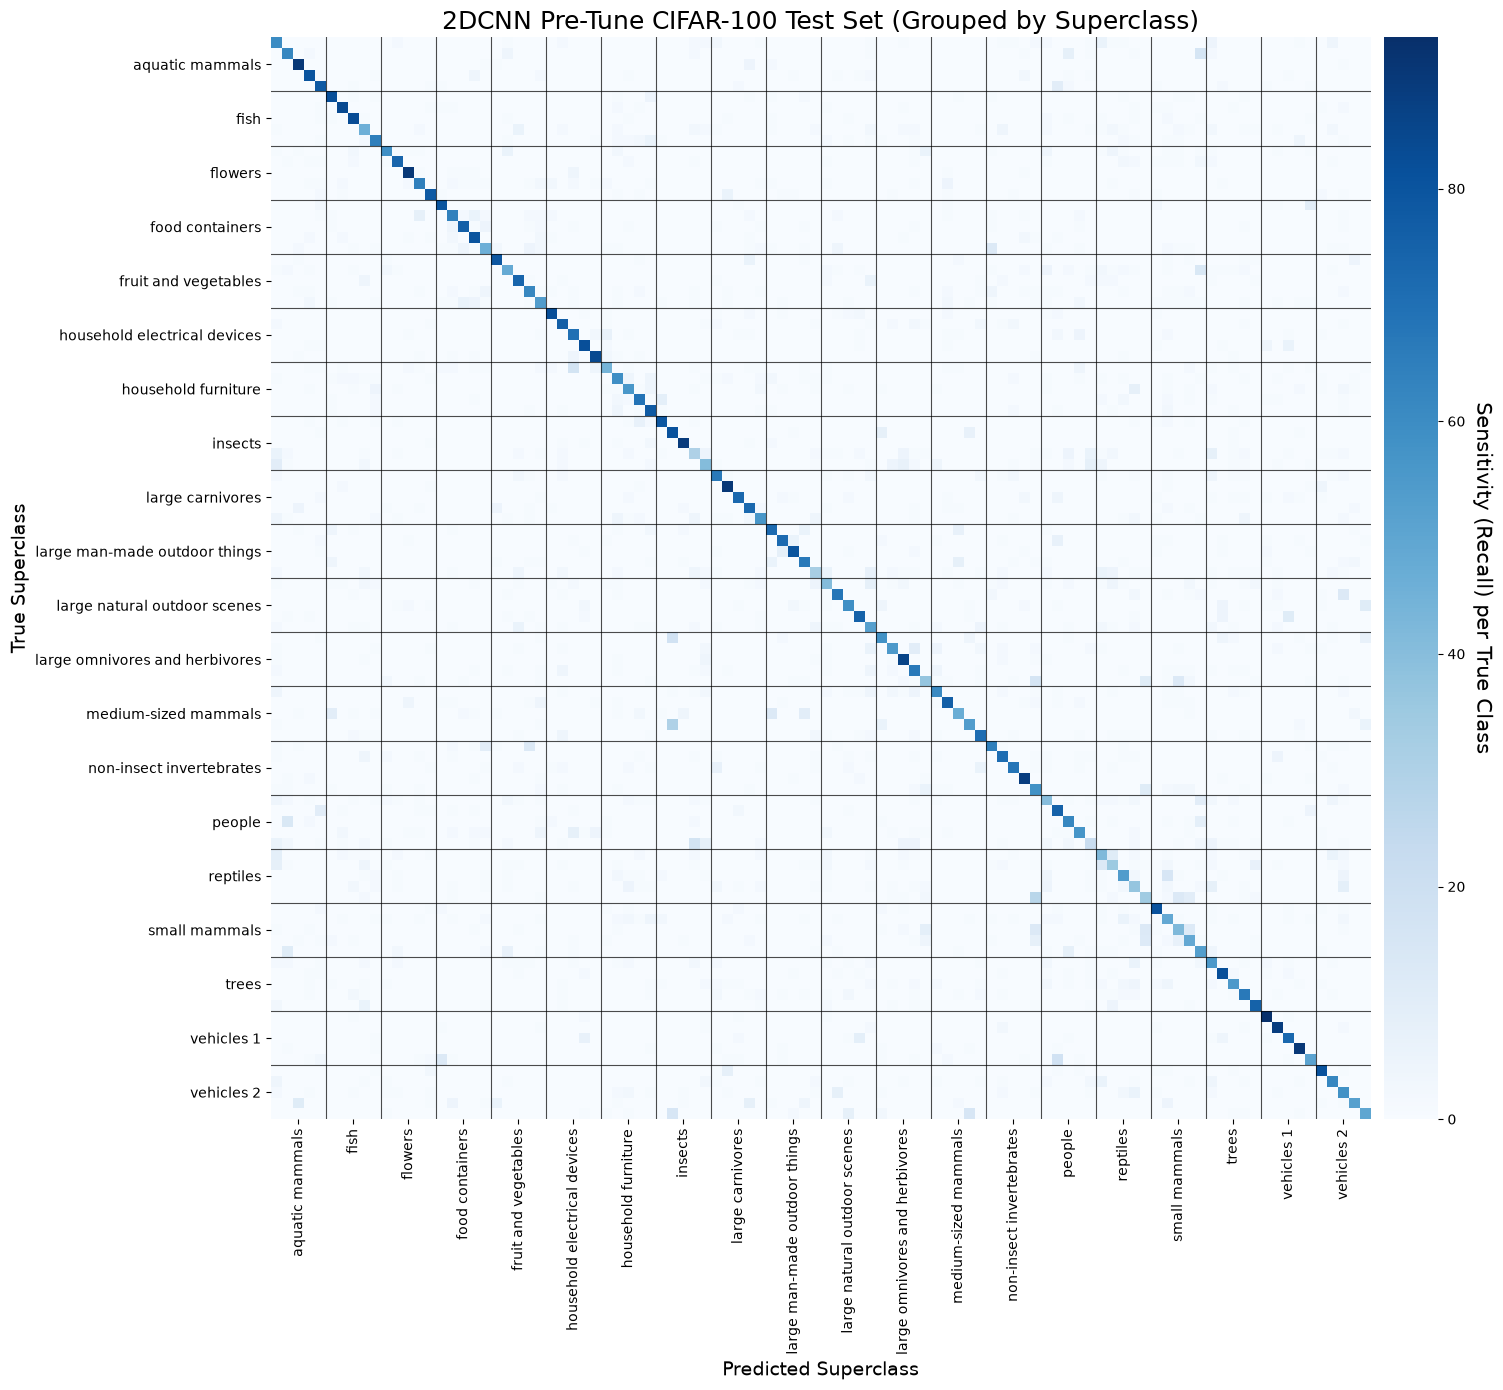


2DCNN Pre-Tune Total Misclassified Samples: 3518 / 10000


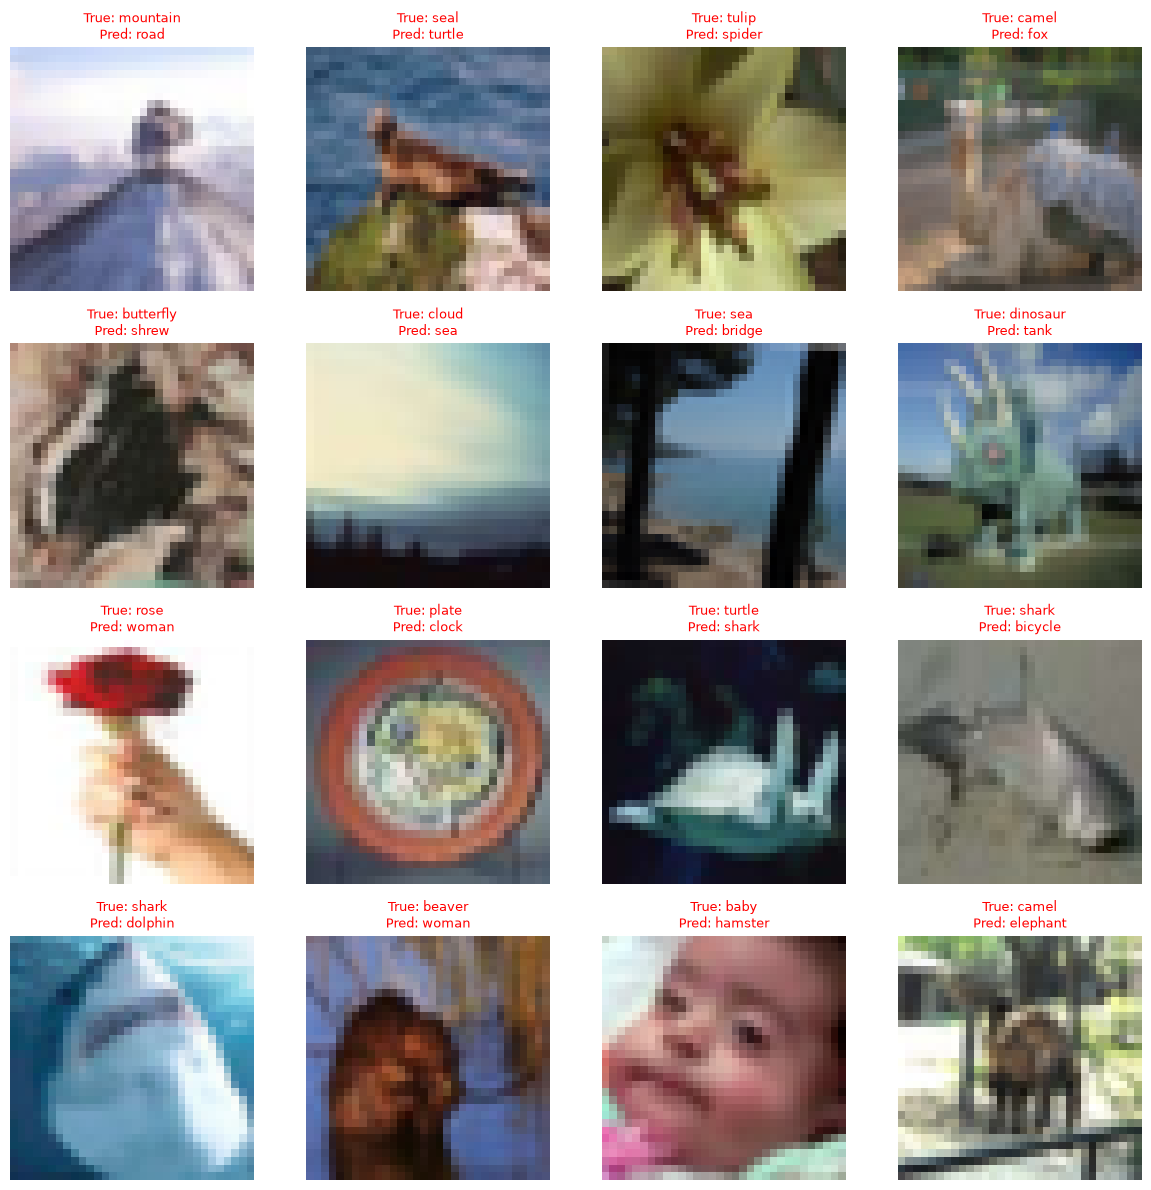

In [6]:
baseline_ckpt = os.path.join(CKPT_DIR, "cnn_baseline.pt")
baseline_model = make_cnn(BASELINE["dropout_rate"])

if os.path.exists(baseline_ckpt):
    print(f"Found checkpoint: loading {baseline_ckpt}")
    base_history, pre_train_s = load_run(baseline_ckpt, baseline_model)
    if pre_train_s is None:
        print("  (checkpoint has no stored train time: delete it and re-run to record one)")
else:
    print("No checkpoint found: training the pre-tune model")
    t0 = time.perf_counter()
    base_history = fit(
        baseline_model, lr=BASELINE["lr"], weight_decay=BASELINE["weight_decay"],
        batch_size=BASELINE["batch_size"], epochs=EPOCHS, patience=PATIENCE, desc="Pre-tune",
    )
    pre_train_s = time.perf_counter() - t0
    save_run(baseline_ckpt, baseline_model, base_history, pre_train_s)

plot_curves(base_history, "2DCNN")
pre_tune_test_loss, pre_tune_test_acc, pre_preds, pre_test_s = timed_test(baseline_model, X_test, y_test)
print(f"\nFinal 2DCNN Test Acc: {pre_tune_test_acc:.2f}% (Loss: {pre_tune_test_loss:.4f})")
pre_results = save_model_csv("2DCNN", base_history, y_test_np, pre_preds, pre_train_s, pre_test_s)
plot_diagnostics(pre_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="2DCNN Pre-Tune")

## Logistic-regression baseline

Logistic regression: 100%|██████████| 50/50 [00:50<00:00,  1.01s/epoch, tr_loss=3.999, val_acc=12.82%, val_loss=4.119] 


Final Logistic Regression Test Acc: 12.72% (Loss: 4.1583)
Saved logistic_regression_history.csv and logistic_regression_metrics.csv -> results/


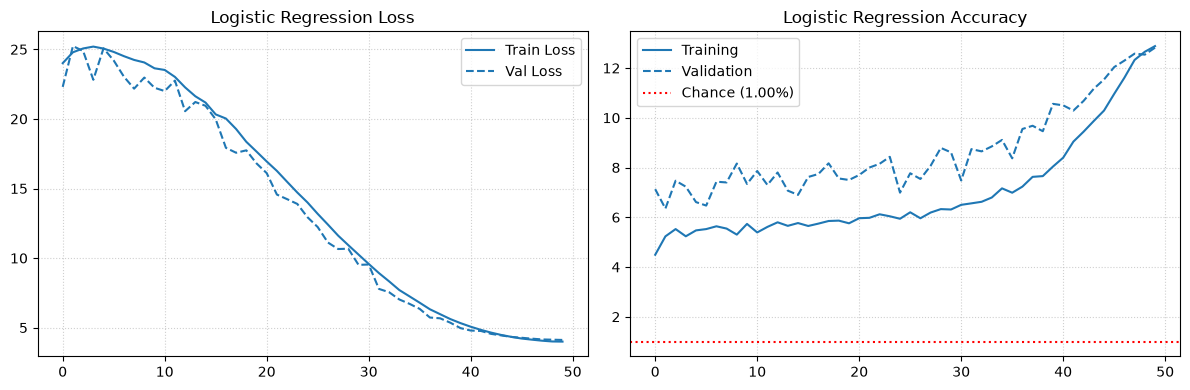

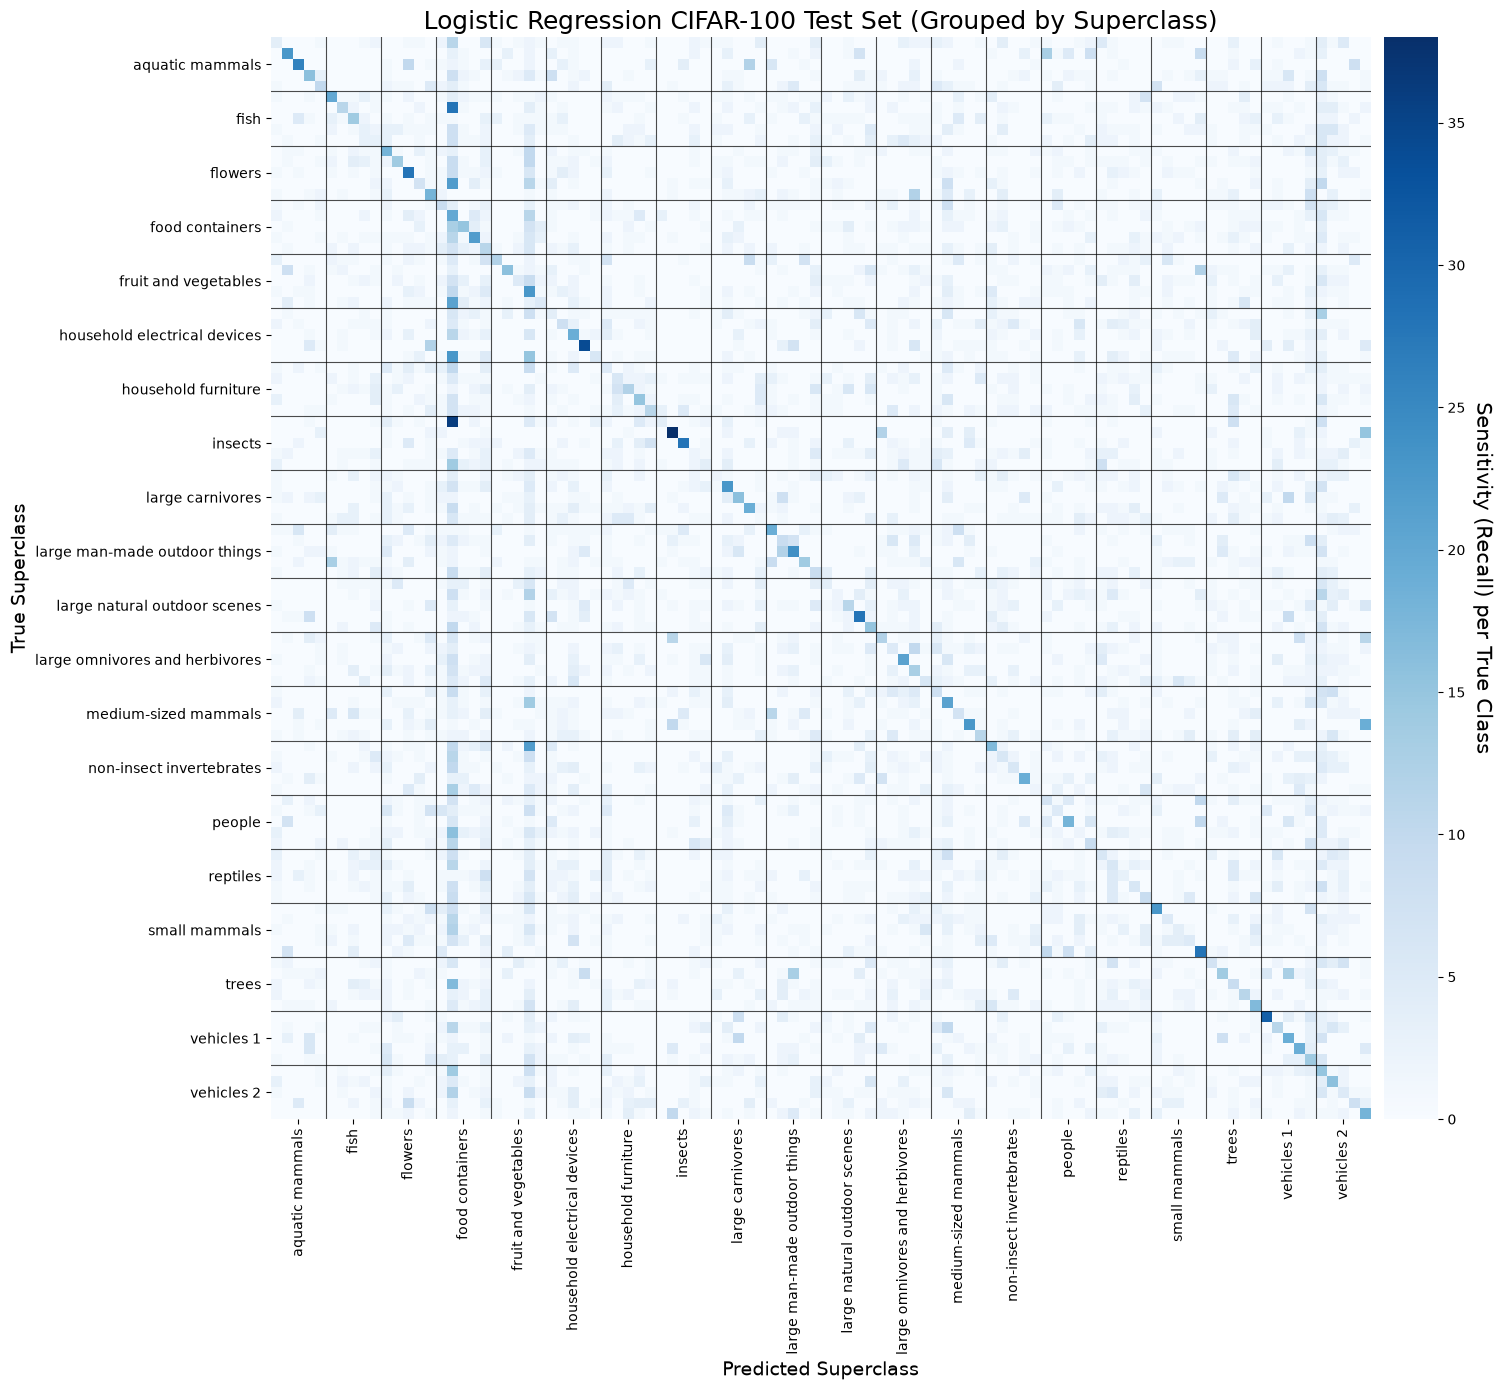


Logistic Regression Total Misclassified Samples: 8728 / 10000


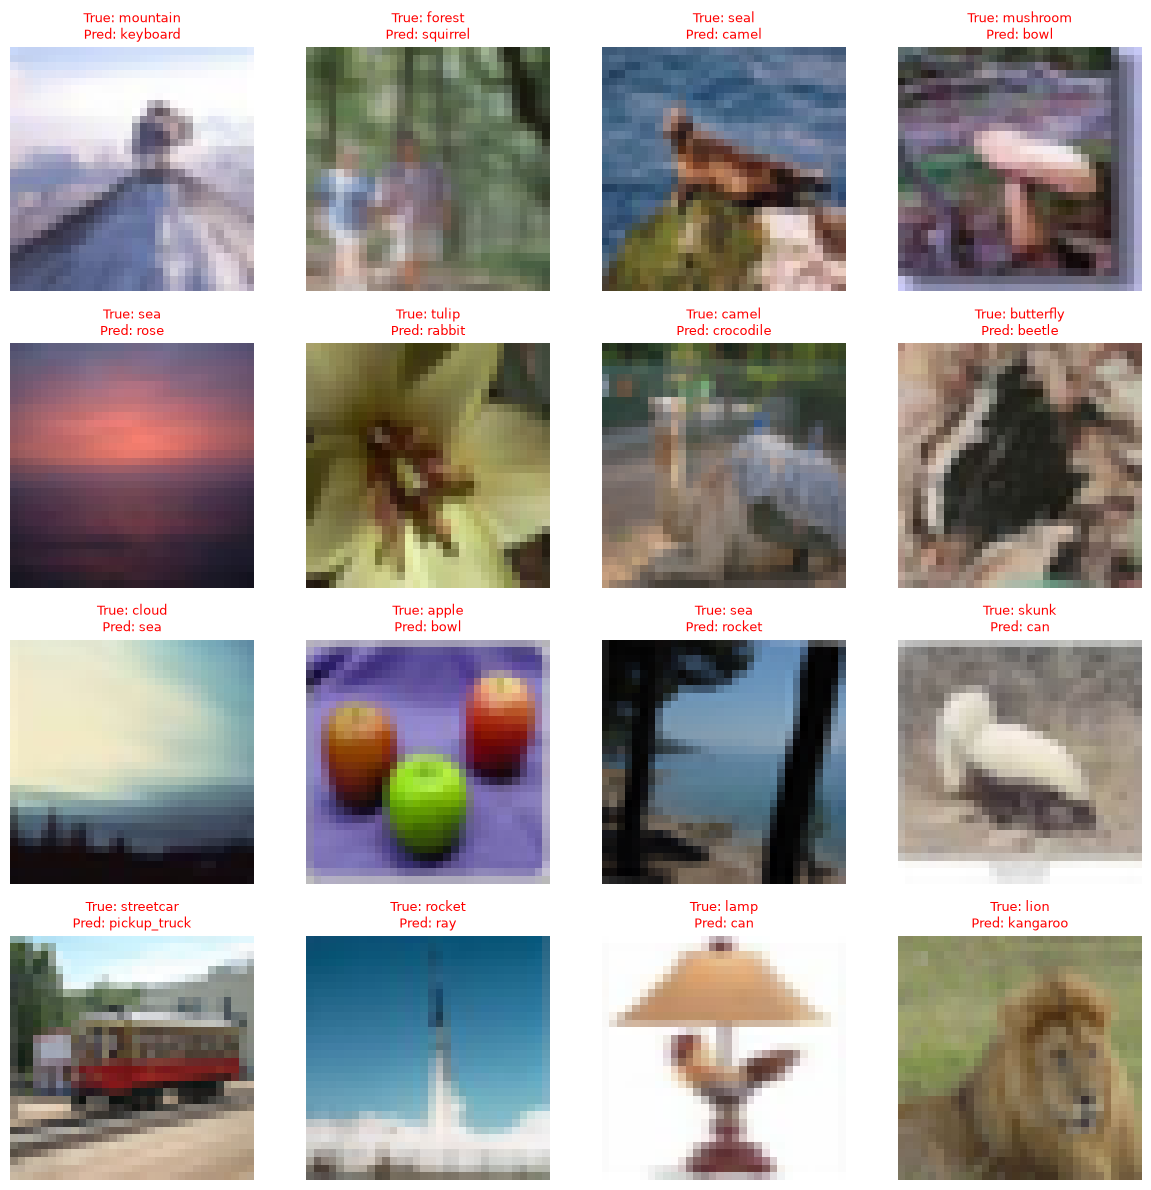

In [7]:
lr_baseline = make_logreg()
t0 = time.perf_counter()
lr_history = fit(
    lr_baseline, lr=LOGREG["lr"], weight_decay=LOGREG["weight_decay"],
    batch_size=LOGREG["batch_size"], epochs=EPOCHS, patience=PATIENCE, desc="Logistic regression",
)
lr_train_s = time.perf_counter() - t0
lr_test_loss, lr_test_acc, lr_preds, lr_test_s = timed_test(lr_baseline, X_test, y_test)
print(f"\nFinal Logistic Regression Test Acc: {lr_test_acc:.2f}% (Loss: {lr_test_loss:.4f})")
lr_results = save_model_csv("Logistic Regression", lr_history, y_test_np, lr_preds, lr_train_s, lr_test_s)

plot_curves(lr_history, "Logistic Regression")
plot_diagnostics(lr_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="Logistic Regression")

Found checkpoint: loading checkpoints\effnet_baseline.pt


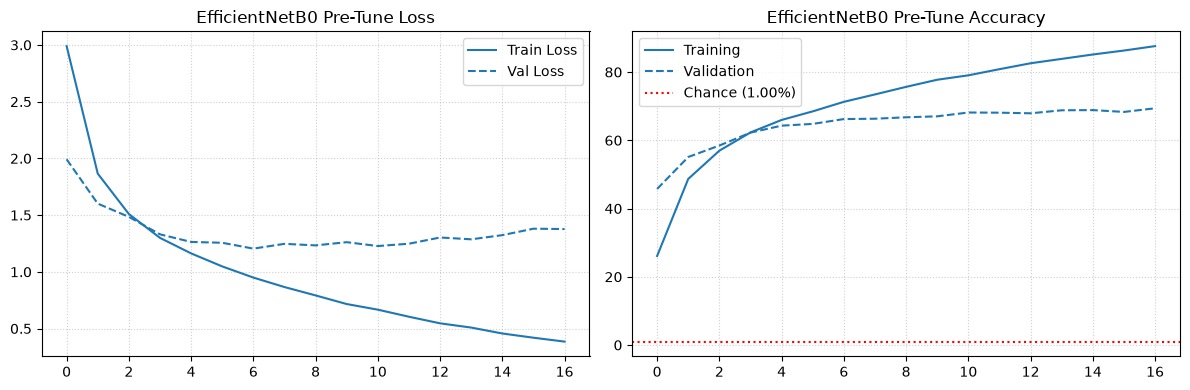


Final EfficientNetB0 Pre-Tune Test Acc: 66.69% (Loss: 1.1983)
Saved efficientnetb0_pre-tune_history.csv and efficientnetb0_pre-tune_metrics.csv -> results/


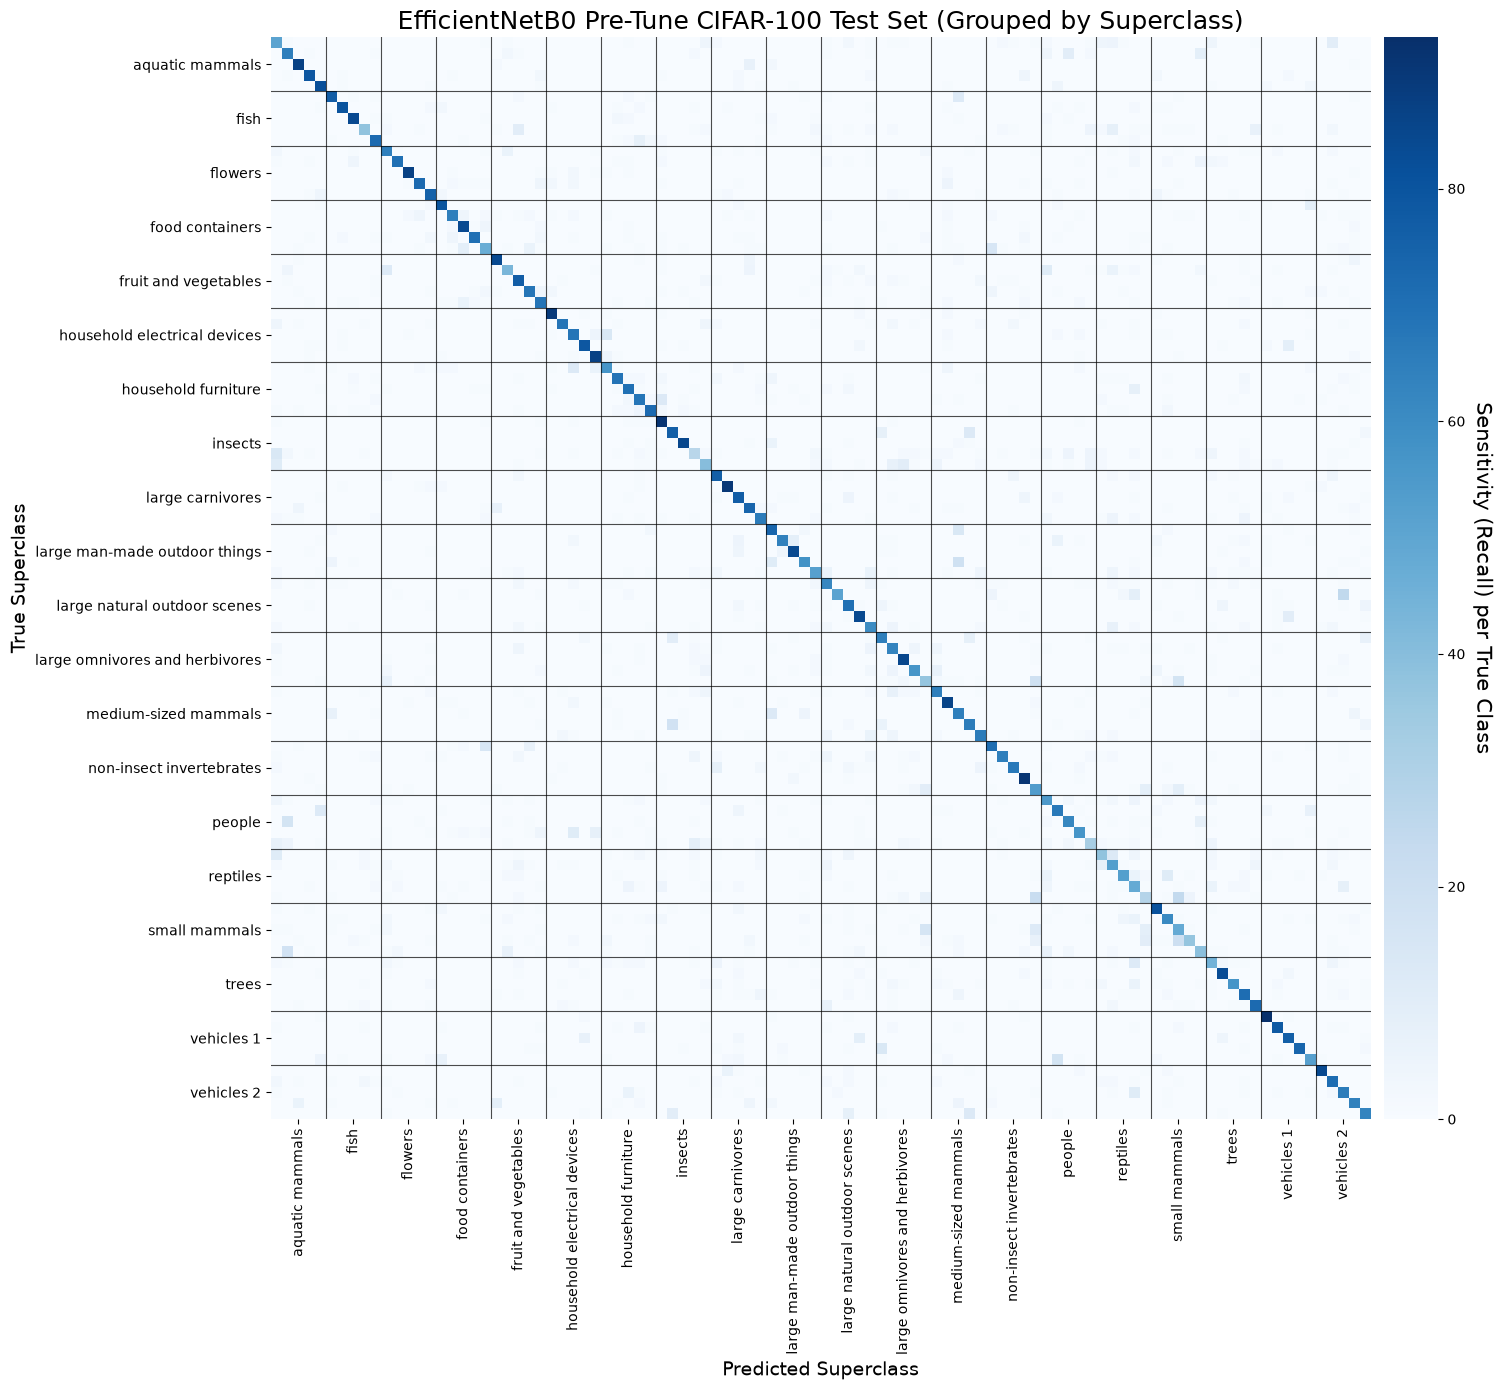


EfficientNetB0 Pre-Tune Total Misclassified Samples: 3331 / 10000


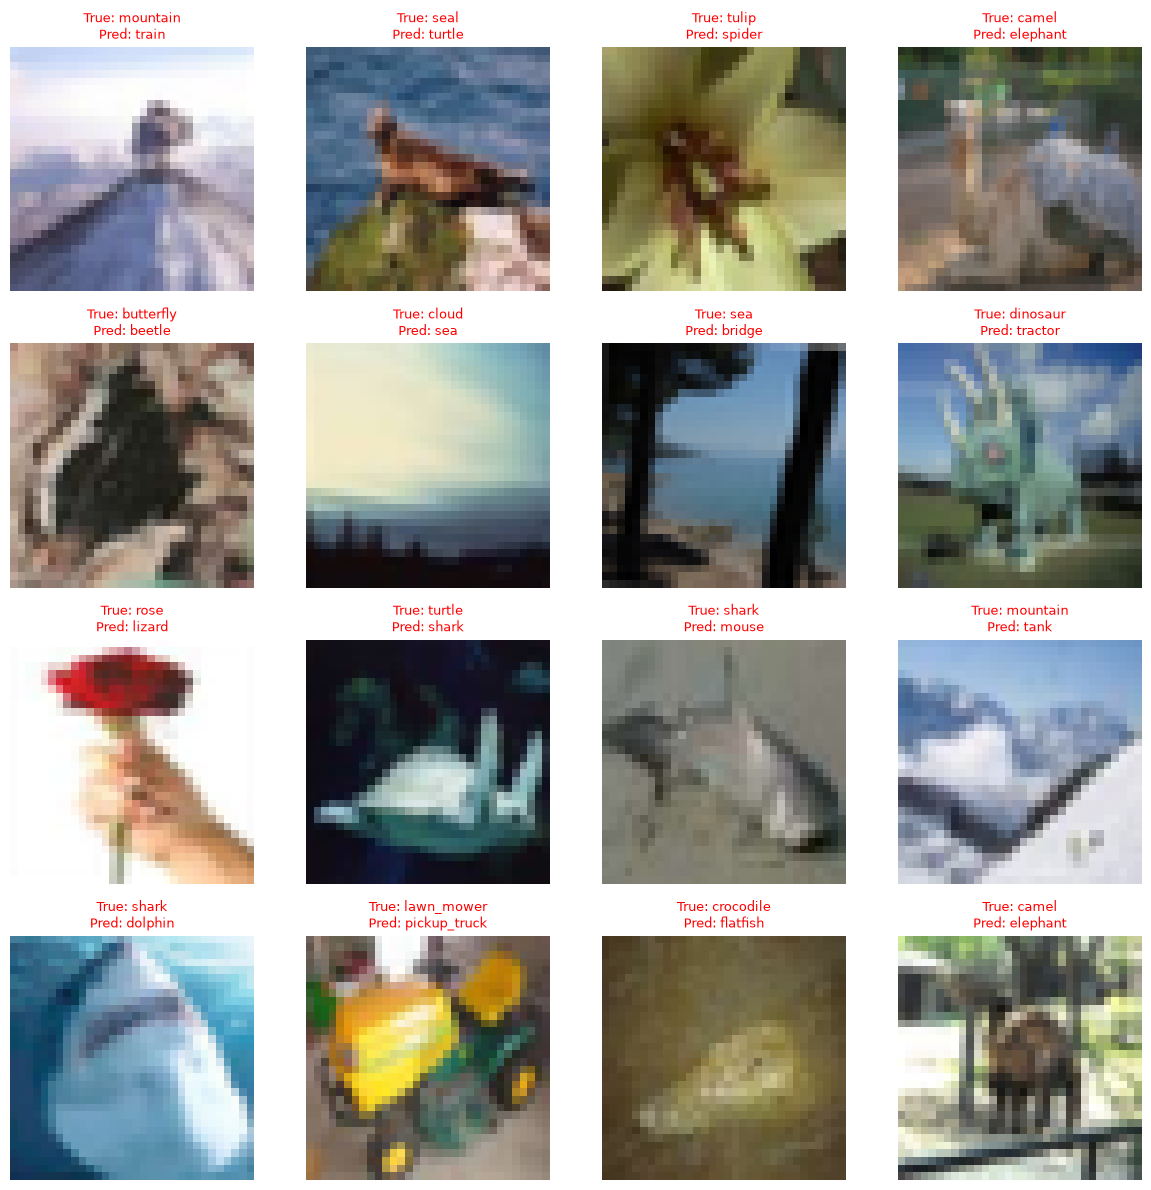

In [8]:
# Instantiate and drop it into your existing pipeline
effnet_ckpt = os.path.join(CKPT_DIR, "effnet_baseline.pt")
effnet_model = make_efficientnet()

if os.path.exists(effnet_ckpt):
    print(f"Found checkpoint: loading {effnet_ckpt}")
    eff_base_history, pre_train_s = load_run(effnet_ckpt, effnet_model)
    if pre_train_s is None:
        print("(checkpoint has no stored train time: delete it and re-run to record one)")
else:
    print("No checkpoint found: training the EfficientNet model")
    t0 = time.perf_counter()
    eff_base_history = fit(
        effnet_model, 
        lr=BASELINE["lr"], 
        weight_decay=BASELINE["weight_decay"],
        batch_size=BASELINE["batch_size"], 
        epochs=EPOCHS, 
        patience=PATIENCE, 
        desc="EfficientNet Pre-tune",
    )
    pre_train_s = time.perf_counter() - t0
    save_run(effnet_ckpt, effnet_model, eff_base_history, pre_train_s)

# Evaluate and save using your exact functions
plot_curves(eff_base_history, "EfficientNetB0 Pre-Tune")
MODEL_COLORS["EfficientNetB0 Pre-Tune"] = "#ff7f0e"  # Orange

eff_test_loss, eff_test_acc, eff_preds, eff_test_s = timed_test(effnet_model, X_test, y_test)
print(f"\nFinal EfficientNetB0 Pre-Tune Test Acc: {eff_test_acc:.2f}% (Loss: {eff_test_loss:.4f})")

eff_results = save_model_csv("EfficientNetB0 Pre-Tune", eff_base_history, y_test_np, eff_preds, pre_train_s, eff_test_s)
plot_diagnostics(eff_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="EfficientNetB0 Pre-Tune")

## Optuna search

In [9]:
def objective(trial, which_model: str = "cnn"):
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    dropout_rate = trial.suggest_float("dropout_rate", 0.2, 0.6, step=0.1)
    weight_decay = trial.suggest_float("weight_decay", 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", BATCH_SIZES)

    if which_model == "cnn":
        model = make_cnn(dropout_rate)
    elif which_model == "efficientnet":
        model = make_efficientnet(dropout_rate)
    else:
        raise ValueError(f"Unknown model type: {which_model}")

    try:
        history = fit(
            model, lr=lr, weight_decay=weight_decay, batch_size=batch_size,
            epochs=N_EPOCHS, trial=trial, verbose=False,   
        )
    finally:
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()                        
            
    return history["val_acc"][-1]


def tqdm_callback(study, trial):
    pbar.update(1)
    try:
        best = f"{study.best_value:.2f}%"  
    except ValueError:
        best = "N/A"
    pbar.set_postfix(best_acc=best)

In [10]:
import json

CHECKPOINT_PATH = "optuna_efficientnet_best.json"

if os.path.exists(CHECKPOINT_PATH):
    print(f"Found checkpoint: Loading existing results from {CHECKPOINT_PATH}")
    with open(CHECKPOINT_PATH, "r") as f:
        checkpoint = json.load(f)

    best_params = checkpoint["best_params"]
    best_value = checkpoint["best_value"]
    optuna_s = checkpoint["optuna_s"]

    print(f"Optuna search time (cached): {optuna_s / 60:.2f} min")
    print(f"Best val accuracy: {best_value:.2f}%")
    print("Best hyperparameters:")
    for key, value in best_params.items():
        print(f"  {key}: {value}")

else:
    print("No checkpoint found. Running full Optuna optimization...")
    pbar = tqdm(total=N_TRIALS, desc="Optuna Optimization Progress")

    def tqdm_callback(study, trial):
        pbar.update(1)
        try:
            best = f"{study.best_value:.2f}%"
        except ValueError:
            best = "N/A"
        pbar.set_postfix(best_acc=best)

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        pruner=optuna.pruners.HyperbandPruner(
            min_resource=1, max_resource=N_EPOCHS, reduction_factor=3
        ),
    )

    t0 = time.perf_counter()
    try:
        study.optimize(
            lambda trial: objective(trial, which_model="efficientnet"),
            n_trials=N_TRIALS,
            callbacks=[tqdm_callback],
        )
    finally:
        pbar.close()
        optuna_s = time.perf_counter() - t0

    best_params = study.best_params
    best_value = study.best_value

    # Save checkpoint to disk
    checkpoint_data = {
        "best_params": best_params,
        "best_value": float(best_value),
        "optuna_s": float(optuna_s),
    }
    with open(CHECKPOINT_PATH, "w") as f:
        json.dump(checkpoint_data, f, indent=4)

    print(f"Optuna search time: {optuna_s / 60:.2f} min")
    print(f"Best val accuracy: {best_value:.2f}%")
    print("Best hyperparameters:")
    for key, value in best_params.items():
        print(f"  {key}: {value}")

Found checkpoint: Loading existing results from optuna_efficientnet_best.json
Optuna search time (cached): 107.17 min
Best val accuracy: 72.29%
Best hyperparameters:
  lr: 0.0005134369783823349
  dropout_rate: 0.4
  weight_decay: 0.00010607190802583915
  batch_size: 32


## Final tuned model (same pipeline as the Pre-Tuned)

Found trained model checkpoint at 'checkpoints\tuned.pt'. Skipping fit...
Saved tuned_history.csv and tuned_metrics.csv -> results/


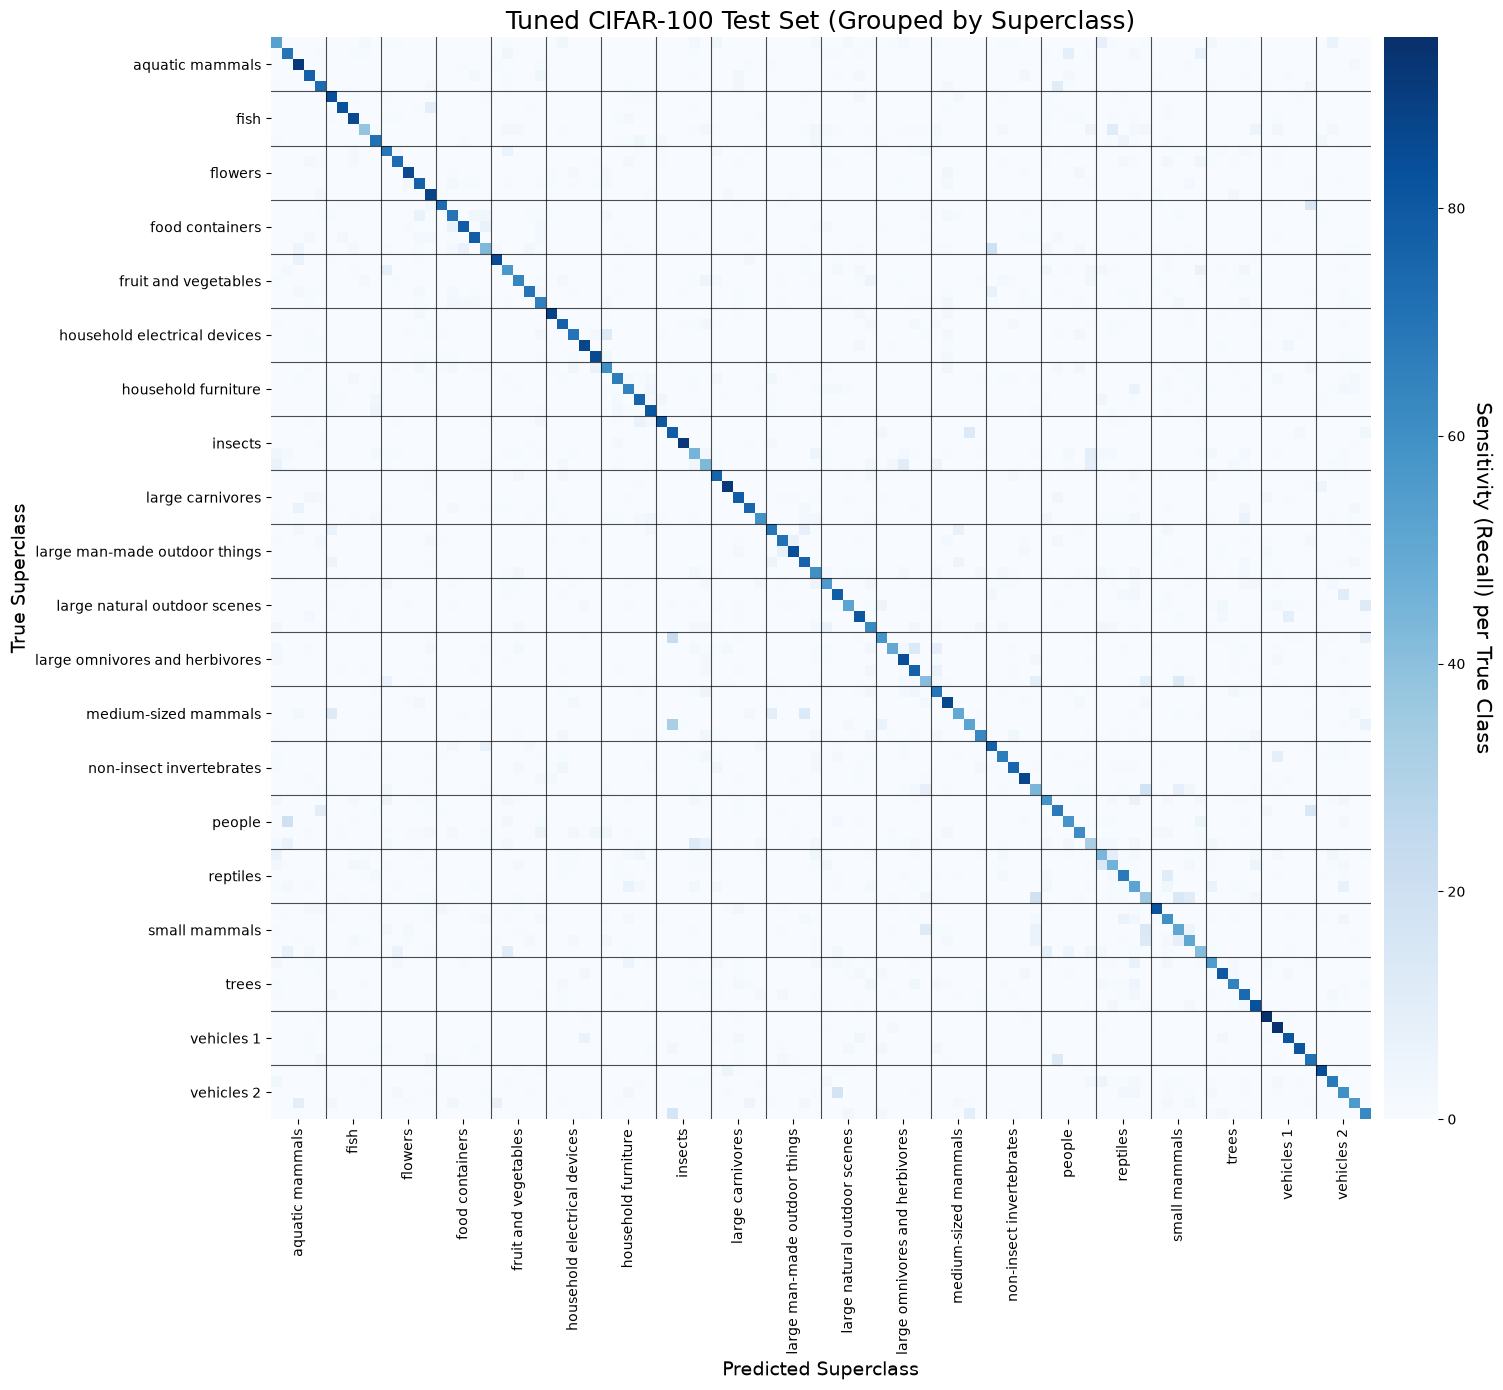


Tuned Total Misclassified Samples: 3131 / 10000


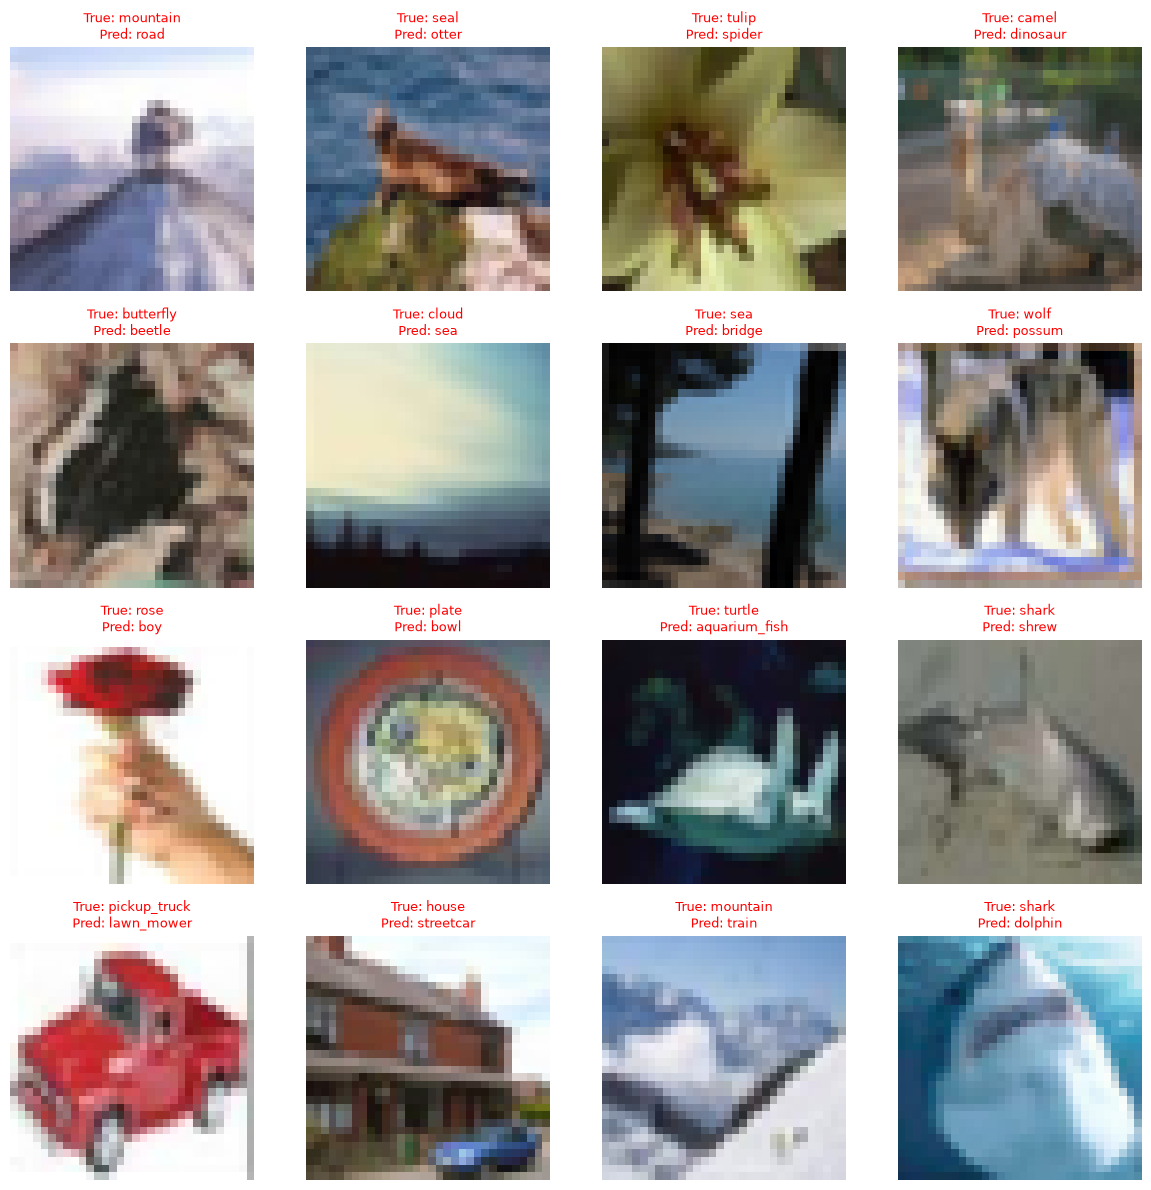

In [11]:
tuned_ckpt = os.path.join(CKPT_DIR, "tuned.pt")
tuned_model = make_efficientnet(best_params["dropout_rate"]).to(device)

if os.path.exists(tuned_ckpt):
    print(f"Found trained model checkpoint at '{tuned_ckpt}'. Skipping fit...")
    checkpoint = torch.load(tuned_ckpt, map_location=device)

    # Extract state_dict based on your actual save_run keys
    if isinstance(checkpoint, dict) and "model" in checkpoint:
        state_dict = checkpoint["model"]
        if isinstance(state_dict, torch.nn.Module):
            tuned_model = state_dict
        else:
            tuned_model.load_state_dict(state_dict)
            
        tuned_history = checkpoint.get("history", {})
        tuned_train_s = checkpoint.get("train_time_s", checkpoint.get("train_s", optuna_s))
        
    elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        tuned_model.load_state_dict(checkpoint["model_state_dict"])
        tuned_history = checkpoint.get("history", {})
        tuned_train_s = checkpoint.get("train_s", optuna_s)
        
    else:
        # Fallback for raw state_dict
        tuned_model.load_state_dict(checkpoint)
        tuned_history = {}
        tuned_train_s = optuna_s

else:
    print("No existing model checkpoint found. Retraining tuned EfficientNet...")
    t0 = time.perf_counter()
    tuned_history = fit(
        tuned_model,
        lr=best_params["lr"],
        weight_decay=best_params["weight_decay"],
        batch_size=best_params["batch_size"],
        epochs=EPOCHS,
        patience=PATIENCE,
        desc="Tuned",
    )
    final_fit_s = time.perf_counter() - t0
    tuned_train_s = optuna_s + final_fit_s

    save_run(tuned_ckpt, tuned_model, tuned_history, tuned_train_s)
    print(
        f"Tuned train time: {tuned_train_s / 60:.2f} min (Optuna"
        f" {optuna_s / 60:.2f} + final fit {final_fit_s / 60:.2f})"
    )

# Run evaluation downstream
test_loss, test_acc, tuned_preds, tuned_test_s = timed_test(
    tuned_model, X_test, y_test
)
tuned_results = save_model_csv(
    "Tuned",
    tuned_history,
    y_test_np,
    tuned_preds,
    tuned_train_s,
    tuned_test_s,
)
plot_diagnostics(
    tuned_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="Tuned"
)

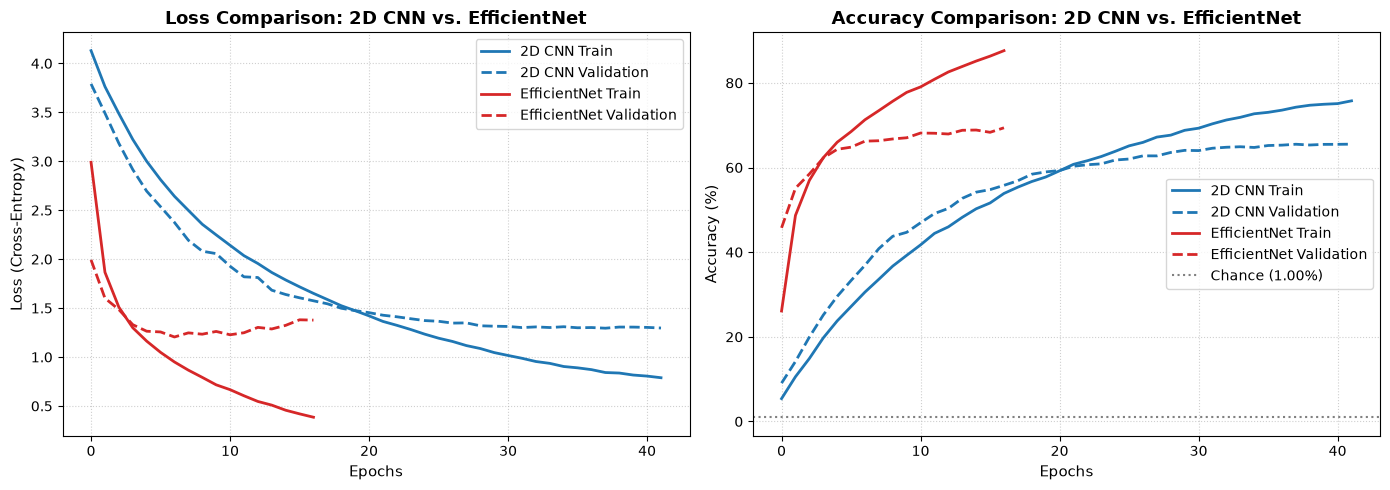

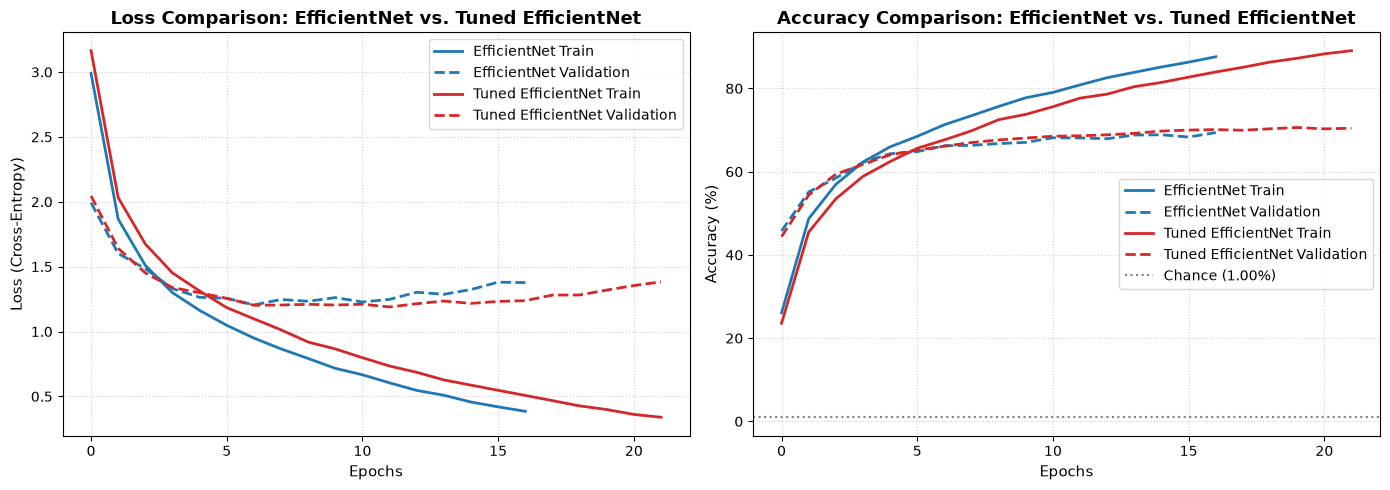

In [12]:
plot_comparison_curves(base_history, eff_base_history, model_names=["2D CNN", "EfficientNet"])
plot_comparison_curves(eff_base_history, tuned_history, model_names=["EfficientNet", "Tuned EfficientNet"])

In [13]:
print("\n--- Model Performance Comparison ---")
print(f"Chance accuracy: {DUMMY_ACC:.2f}%")
# print(f"Logistic regression: {lr_test_acc:.2f}% (Loss: {lr_test_loss:.4f})")
print(f"EfficientNetB0: {eff_test_acc:.2f}% (Loss: {eff_test_loss:.4f})")
print(f"2D CNN: {pre_tune_test_acc:.2f}% (Loss: {pre_tune_test_loss:.4f})")
print(f"After tuning (EfficientNetB0): {test_acc:.2f}% (Loss: {test_loss:.4f})")
print(f"Accuracy difference: {test_acc - eff_test_acc:+.2f}%")


--- Model Performance Comparison ---
Chance accuracy: 1.00%
EfficientNetB0: 66.69% (Loss: 1.1983)
2D CNN: 64.82% (Loss: 1.2812)
After tuning (EfficientNetB0): 68.69% (Loss: 1.1740)
Accuracy difference: +2.00%


## Final comparison: metrics and time

,accuracy,precision,recall,f1,train_time_min,test_time_min
model,,,,,,
2DCNN,64.82,64.95,64.82,64.52,9.40,0.03
Tuned,68.69,69.11,68.69,68.47,122.99,0.01
EfficientNetB0 Pre-Tune,66.69,67.84,66.69,66.59,8.09,0.12
Logistic Regression,12.72,14.98,12.72,13.08,0.84,0.00


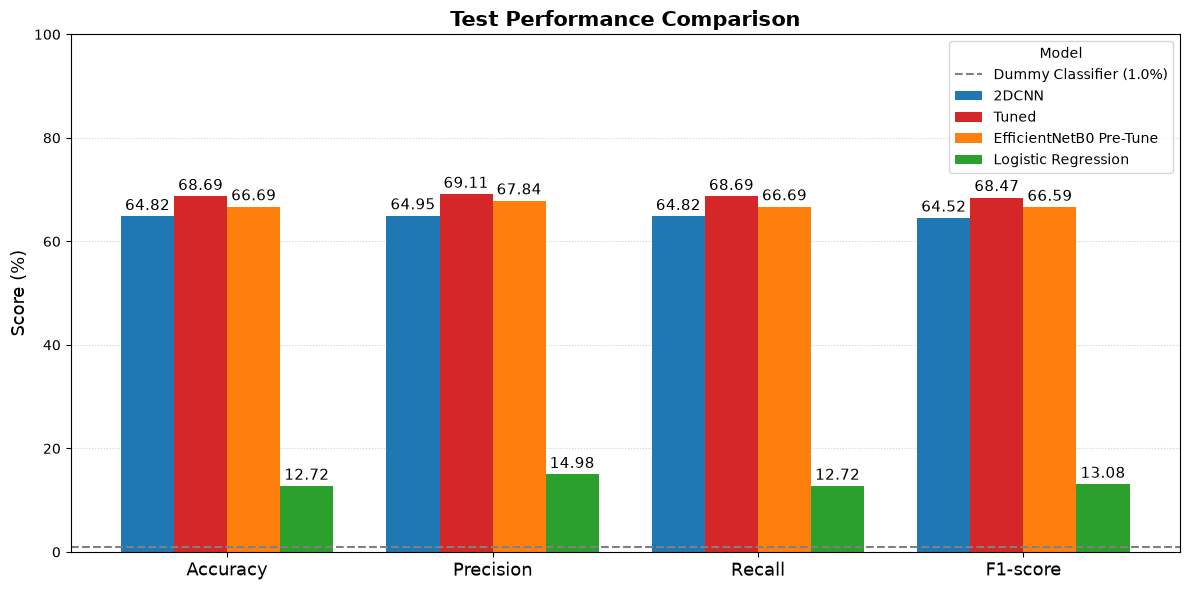

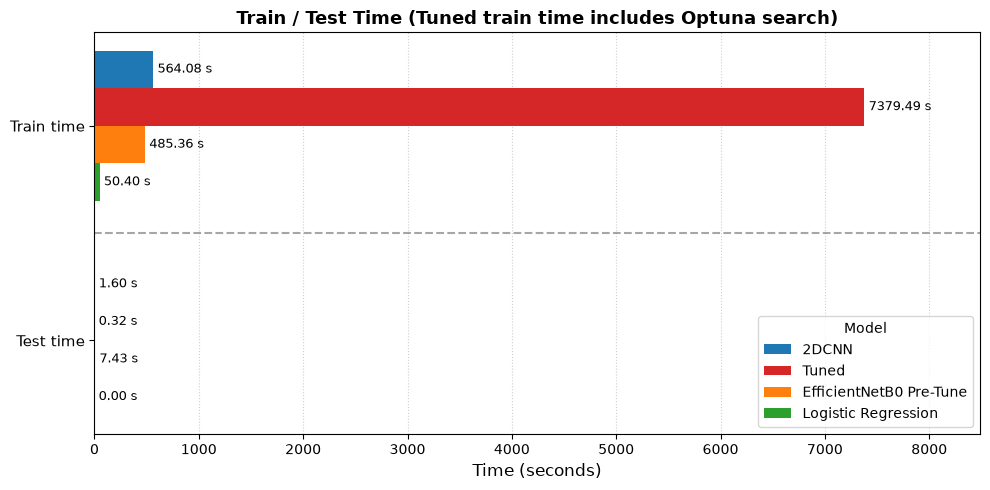

In [22]:
all_results = [pre_results, tuned_results, eff_results, lr_results]
pd.DataFrame(all_results).to_csv(os.path.join(RESULTS_DIR, "all_models_summary.csv"), index=False)
display(pd.DataFrame(all_results).set_index("model").round(2))

plot_metric_comparison(all_results)
plot_time_comparison(all_results)